# Stage 2: تصنيف نوع الجذام (Tuberculoid / Lepromatous / Borderline)
### مقارنة استراتيجيتين للتهيئة (ImageNet مقابل Stage-1) عبر Stratified 5-Fold CV

**الفكرة:** بعد Stage 1 (جذام / مش جذام)، المرحلة دي بتاخد بس صور الجذام
(672 صورة) وتصنفها لنوعها الثلاثة. بما إن البيانات قليلة جدًا لكل نوع،
هنستخدم **Stratified K-Fold Cross Validation** بدل split ثابت.

**التصميم:**
1. نفصل **Hold-out Test set** (15%) بعيد تمامًا عن أي تدريب من الأول
2. الـ 85% الباقيين بيتقسموا لـ **5 Folds** متوازنة (Stratified)
3. لكل Fold، بندرب موديلين: واحد بيبدأ من **ImageNet** والتاني بيبدأ من
   **Backbone موديل Stage-1 المدرب** (transfer learning من موديلنا احنا)
4. نقارن متوسط الأداء (mean ± std) بين الاستراتيجيتين عبر الـ 5 Folds
5. الاستراتيجية الأفضل بنعيد تدريبها على كل بيانات train+val (بدون test)
   ونقيّمها أخيرًا على الـ Hold-out Test (تقييم نهائي غير متحيز)

**المعمارية المستخدمة:** EfficientNet-B3 بس (الأخف والأسرع) - لو حابة تمدّي
التجربة لباقي المعماريات لاحقًا، بس لفّي نفس الكود على قائمة معماريات.


## 1) تركيب المكتبات

In [ ]:
!pip install -q torch torchvision scikit-learn pandas matplotlib seaborn

## 2) ربط Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3) الإعدادات
لازم `STAGE1_CHECKPOINT_PATH` يشاور على checkpoint حقيقي اتدرب في Stage 1
(نفس الـ EfficientNet-B3 بتاع Stage 1) عشان استراتيجية "from Stage-1" تشتغل.

In [ ]:
import os

RAW_DATA_DIR = "/content/drive/MyDrive/Atlas dan ISIC2019 (31 classes)"

# ترتيب الكلاسات ثابت ومهم (index بيتحدد بيه في كل مكان)
LEPROSY_SUBTYPES = ["Leprosy Tuberculoid", "Leprosy Lepromatous", "Leprosy Borderline"]
SUBTYPE_TO_IDX = {name: i for i, name in enumerate(LEPROSY_SUBTYPES)}
IDX_TO_SUBTYPE = {i: name for name, i in SUBTYPE_TO_IDX.items()}
NUM_CLASSES = len(LEPROSY_SUBTYPES)

PROJECT_DIR = "/content/drive/MyDrive/skin_disease_project"
STAGE1_CHECKPOINT_PATH = os.path.join(PROJECT_DIR, "outputs/checkpoints/efficientnet_b3_best.pt")

STAGE2_DIR = os.path.join(PROJECT_DIR, "stage2_leprosy_subtype")
CHECKPOINTS_DIR = os.path.join(STAGE2_DIR, "checkpoints")
LOGS_DIR = os.path.join(STAGE2_DIR, "logs")
PLOTS_DIR = os.path.join(STAGE2_DIR, "plots")
RESULTS_DIR = os.path.join(STAGE2_DIR, "results")

for d in [CHECKPOINTS_DIR, LOGS_DIR, PLOTS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

HOLD_OUT_TEST_RATIO = 0.15
N_FOLDS = 5
RANDOM_SEED = 42

ARCHITECTURE = "efficientnet_b3"
IMAGE_SIZE = 300
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.4
LABEL_SMOOTHING = 0.1
EARLY_STOPPING_PATIENCE = 8
LR_SCHEDULER_PATIENCE = 3
FREEZE_BACKBONE_EPOCHS = 5

INIT_STRATEGIES = ["imagenet", "stage1_finetuned"]

print("الإعدادات جاهزة ✅")
print(f"Stage-1 checkpoint المستخدم: {STAGE1_CHECKPOINT_PATH}")
print(f"موجود؟ {os.path.exists(STAGE1_CHECKPOINT_PATH)}")


الإعدادات جاهزة ✅
Stage-1 checkpoint المستخدم: /content/drive/MyDrive/skin_disease_project/outputs/checkpoints/efficientnet_b3_best.pt
موجود؟ True


## 4) فحص Drive (مساحة + اتصال) قبل أي تدريب
نفس الفحص اللي عملناه في Stage 1 - لتفادي تكرار مشكلة الـ checkpoint الضايع.

In [ ]:
import shutil

def gb(x):
    return x / (1024 ** 3)

is_really_mounted = os.path.ismount("/content/drive")
print(f"هل Drive متصلة فعليًا؟ {is_really_mounted}")

total, used, free = shutil.disk_usage("/content/drive/MyDrive")
print(f"مساحة Drive المتاحة: {gb(free):.2f} GB")
if gb(free) < 1:
    print("⚠️  تحذير: مساحة قليلة جدًا!")
else:
    print("✅ المساحة كويسة.")


هل Drive متصلة فعليًا؟ True
مساحة Drive المتاحة: 9.81 GB
✅ المساحة كويسة.


## 5) تجميع صور الجذام الثلاثة أنواع فقط (بدون باقي الـ28 مرض)

In [ ]:
from collections import defaultdict

VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def collect_leprosy_subtype_images():
    images = []  # list of (path, label_idx)
    for root, dirs, files in os.walk(RAW_DATA_DIR):
        class_name = os.path.basename(root)
        if class_name not in SUBTYPE_TO_IDX:
            continue
        image_files = [f for f in files if f.lower().endswith(VALID_EXTS)]
        label_idx = SUBTYPE_TO_IDX[class_name]
        for fname in image_files:
            images.append((os.path.join(root, fname), label_idx))
    return images

all_leprosy_images = collect_leprosy_subtype_images()
print(f"إجمالي صور الجذام (كل الأنواع): {len(all_leprosy_images)}")

from collections import Counter
counts = Counter(label for _, label in all_leprosy_images)
for idx, name in IDX_TO_SUBTYPE.items():
    print(f"  {name}: {counts[idx]} صورة")


إجمالي صور الجذام (كل الأنواع): 672
  Leprosy Tuberculoid: 234 صورة
  Leprosy Lepromatous: 293 صورة
  Leprosy Borderline: 145 صورة


## 6) فصل Hold-out Test (15%) + الباقي لـ K-Fold

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold

paths = np.array([p for p, _ in all_leprosy_images])
labels = np.array([l for _, l in all_leprosy_images])

# Hold-out test مفصول تمامًا - هيتشاف مرة واحدة بس في الآخر
pool_paths, test_paths, pool_labels, test_labels = train_test_split(
    paths, labels, test_size=HOLD_OUT_TEST_RATIO, stratify=labels, random_state=RANDOM_SEED
)

print(f"Pool (train+val عبر الـ Folds): {len(pool_paths)} صورة")
print(f"Hold-out Test (منفصل تمامًا): {len(test_paths)} صورة")

print("\nتوزيع الـ Hold-out Test:")
for idx, name in IDX_TO_SUBTYPE.items():
    print(f"  {name}: {(test_labels == idx).sum()} صورة")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
fold_indices = list(skf.split(pool_paths, pool_labels))
print(f"\nتم تقسيم الـ Pool لـ {N_FOLDS} Folds متوازنة (Stratified).")


Pool (train+val عبر الـ Folds): 571 صورة
Hold-out Test (منفصل تمامًا): 101 صورة

توزيع الـ Hold-out Test:
  Leprosy Tuberculoid: 35 صورة
  Leprosy Lepromatous: 44 صورة
  Leprosy Borderline: 22 صورة

تم تقسيم الـ Pool لـ 5 Folds متوازنة (Stratified).


## 7) Dataset مخصص + Transforms (augmentation)

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from PIL import Image

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def get_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(degrees=20),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.9, 1.1)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        transforms.RandomErasing(p=0.15),
    ])
    eval_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return train_transform, eval_transform


class LeprosySubtypeDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        img = self.transform(img)
        return img, int(self.labels[idx])


def build_weighted_sampler(labels):
    labels_t = torch.tensor(labels)
    class_counts = torch.bincount(labels_t, minlength=NUM_CLASSES).float()
    class_weights = 1.0 / class_counts.clamp(min=1)
    sample_weights = class_weights[labels_t]
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)


def make_loaders(train_p, train_l, val_p, val_l):
    train_tf, eval_tf = get_transforms()
    train_ds = LeprosySubtypeDataset(train_p, train_l, train_tf)
    val_ds = LeprosySubtypeDataset(val_p, val_l, eval_tf)

    sampler = build_weighted_sampler(train_l)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader

print("Dataset/Transforms جاهزين ✅")


Dataset/Transforms جاهزين ✅


## 8) Model Factory (رأس 3 كلاسات) + تحميل أوزان Stage-1 (Backbone بس)

In [ ]:
import torch.nn as nn
from torchvision import models

def build_stage2_model():
    """EfficientNet-B3 برأس تصنيف 3 كلاسات (بدل 2 زي Stage 1)."""
    model = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
    backbone = model.features
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=DROPOUT_RATE, inplace=True),
        nn.Linear(in_features, NUM_CLASSES),
    )
    return model, backbone


def load_stage1_backbone(model, checkpoint_path):
    """
    بيحمّل بس أوزان الـ backbone من موديل Stage-1 (اللي كان رأسه 2 كلاس)،
    وبيسيب رأس التصنيف الجديد (3 كلاسات) بأوزان عشوائية طازجة (لازم لأن
    الشكل مختلف: 2 مقابل 3 كلاسات فمينفعش نحمّل رأس Stage-1 القديم).
    """
    stage1_state = torch.load(checkpoint_path, map_location="cpu")
    current_state = model.state_dict()

    compatible = {}
    skipped = []
    for k, v in stage1_state.items():
        if k.startswith("classifier"):
            skipped.append(k)  # رأس التصنيف - هنسيبه عشوائي جديد عمدًا
            continue
        if k in current_state and current_state[k].shape == v.shape:
            compatible[k] = v
        else:
            skipped.append(k)

    current_state.update(compatible)
    model.load_state_dict(current_state)

    print(f"   تم تحميل {len(compatible)} طبقة من الـ backbone بنجاح من Stage-1.")
    print(f"   تم تخطي {len(skipped)} طبقة (رأس التصنيف القديم - هيتعلم من جديد).")
    return model


def build_model(init_strategy: str):
    model, backbone = build_stage2_model()
    if init_strategy == "stage1_finetuned":
        if not os.path.exists(STAGE1_CHECKPOINT_PATH):
            raise FileNotFoundError(f"مفيش checkpoint لـ Stage-1 في: {STAGE1_CHECKPOINT_PATH}")
        model = load_stage1_backbone(model, STAGE1_CHECKPOINT_PATH)
    elif init_strategy != "imagenet":
        raise ValueError(f"init_strategy غير معروفة: {init_strategy}")
    return model, backbone


def set_backbone_trainable(backbone, trainable: bool):
    for param in backbone.parameters():
        param.requires_grad = trainable

print("Model factory جاهز ✅")


Model factory جاهز ✅


## 9) EarlyStopping (مع تحقق سلامة الملف) + دالة تدريب Fold واحد

In [ ]:
import time, json
import numpy as np
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt


def get_device():
    return torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

DEVICE = get_device()
print(f"الجهاز: {DEVICE}")


class EarlyStopping:
    def __init__(self, patience, checkpoint_path):
        self.patience = patience
        self.checkpoint_path = checkpoint_path
        self.best_loss = np.inf
        self.counter = 0
        self.should_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.counter = 0
            torch.save(model.state_dict(), self.checkpoint_path)
            try:
                _ = torch.load(self.checkpoint_path, map_location="cpu")
            except Exception as e:
                print(f"   ❌ فشل التحقق من الحفظ: {e}")
                return False
            return True
        self.counter += 1
        if self.counter >= self.patience:
            self.should_stop = True
        return False


def run_epoch(model, loader, criterion, optimizer, device, train_mode):
    model.train() if train_mode else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    torch.set_grad_enabled(train_mode)
    for images, lbls in loader:
        images, lbls = images.to(device), lbls.to(device)
        if train_mode:
            optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, lbls)
        if train_mode:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == lbls).sum().item()
        total += lbls.size(0)
    return total_loss / total, 100.0 * correct / total


def get_val_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, lbls in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.append(preds)
            all_labels.append(lbls.numpy())
    return np.concatenate(all_preds), np.concatenate(all_labels)


def train_one_fold(init_strategy, fold_idx, train_p, train_l, val_p, val_l):
    tag = f"{init_strategy}_fold{fold_idx}"
    print(f"\n{'='*70}\n{tag}\n{'='*70}")

    train_loader, val_loader = make_loaders(train_p, train_l, val_p, val_l)
    model, backbone = build_model(init_strategy)
    model.to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=LR_SCHEDULER_PATIENCE)

    checkpoint_path = os.path.join(CHECKPOINTS_DIR, f"{tag}_best.pt")
    early_stopping = EarlyStopping(EARLY_STOPPING_PATIENCE, checkpoint_path)

    set_backbone_trainable(backbone, trainable=False)

    for epoch in range(1, NUM_EPOCHS + 1):
        if epoch == FREEZE_BACKBONE_EPOCHS + 1:
            set_backbone_trainable(backbone, trainable=True)

        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer, DEVICE, True)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer, DEVICE, False)
        scheduler.step(val_loss)
        improved = early_stopping(val_loss, model)

        if epoch % 5 == 0 or improved:
            flag = " ✅" if improved else ""
            print(f"  Epoch {epoch:03d} | train_acc={train_acc:.1f}% | val_loss={val_loss:.4f} val_acc={val_acc:.1f}%{flag}")

        if early_stopping.should_stop:
            print(f"  ⏹️  Early stopping عند epoch {epoch}")
            break

    # تحميل أفضل نسخة وحساب مقاييس الـ Fold ده
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    preds, true = get_val_predictions(model, val_loader, DEVICE)

    precision, recall, f1, support = precision_recall_fscore_support(
        true, preds, labels=list(range(NUM_CLASSES)), zero_division=0
    )
    macro_f1 = f1.mean()
    acc = accuracy_score(true, preds) * 100

    print(f"  نتيجة الـ Fold: Accuracy={acc:.2f}% | Macro F1={macro_f1*100:.2f}%")

    return {
        "init_strategy": init_strategy, "fold": fold_idx, "accuracy": acc,
        "macro_f1": macro_f1 * 100,
        **{f"f1_{IDX_TO_SUBTYPE[i]}": f1[i] * 100 for i in range(NUM_CLASSES)},
        **{f"recall_{IDX_TO_SUBTYPE[i]}": recall[i] * 100 for i in range(NUM_CLASSES)},
    }

print("دالة تدريب الـ Fold جاهزة ✅")


الجهاز: cuda
دالة تدريب الـ Fold جاهزة ✅


## 10) تشغيل الـ 5-Fold CV لكل استراتيجية (10 تدريبات إجمالًا)
⚠️ الخلية دي هتاخد وقت طويل (5 Folds × 2 استراتيجيات = 10 تدريبات كاملة).
لو الجلسة اتقطعت، تقدري تعيدي تشغيلها من اللي وقفت عنده بتعديل الـ loop.

In [ ]:
import pandas as pd
all_fold_results = []

for init_strategy in INIT_STRATEGIES:
    print(f"\n{'#'*70}\n# استراتيجية: {init_strategy}\n{'#'*70}")
    for fold_idx, (train_idx, val_idx) in enumerate(fold_indices, start=1):
        train_p, val_p = pool_paths[train_idx], pool_paths[val_idx]
        train_l, val_l = pool_labels[train_idx], pool_labels[val_idx]

        result = train_one_fold(init_strategy, fold_idx, train_p, train_l, val_p, val_l)
        all_fold_results.append(result)

        # حفظ تدريجي بعد كل Fold عشان لو الجلسة قفلت منخسرش كل حاجة
        pd.DataFrame(all_fold_results).to_csv(os.path.join(RESULTS_DIR, "kfold_raw_results.csv"), index=False)

print("\n✅ انتهت كل الـ Folds للاستراتيجيتين.")



######################################################################
# استراتيجية: imagenet
######################################################################

imagenet_fold1
  Epoch 001 | train_acc=33.1% | val_loss=1.1023 val_acc=37.4% ✅
  Epoch 002 | train_acc=38.2% | val_loss=1.0818 val_acc=44.3% ✅
  Epoch 003 | train_acc=42.3% | val_loss=1.0619 val_acc=51.3% ✅
  Epoch 004 | train_acc=47.6% | val_loss=1.0506 val_acc=52.2% ✅
  Epoch 005 | train_acc=44.1% | val_loss=1.0451 val_acc=54.8% ✅
  Epoch 006 | train_acc=59.4% | val_loss=0.9667 val_acc=65.2% ✅
  Epoch 007 | train_acc=70.0% | val_loss=0.8496 val_acc=73.0% ✅
  Epoch 008 | train_acc=77.9% | val_loss=0.7402 val_acc=75.7% ✅
  Epoch 009 | train_acc=78.7% | val_loss=0.6777 val_acc=79.1% ✅
  Epoch 010 | train_acc=85.3% | val_loss=0.6484 val_acc=78.3% ✅
  Epoch 012 | train_acc=91.9% | val_loss=0.6458 val_acc=79.1% ✅
  Epoch 013 | train_acc=93.2% | val_loss=0.6441 val_acc=81.7% ✅
  Epoch 015 | train_acc=94.5% | val_loss=0.6174 va

## 11) تجميع النتائج ومقارنة الاستراتيجيتين (Mean ± Std عبر الـ 5 Folds)

مقارنة استراتيجيتي التهيئة (متوسط ± انحراف معياري عبر 5 Folds):
                  Accuracy_mean  Accuracy_std  MacroF1_mean  MacroF1_std
init_strategy                                                           
imagenet                  88.27          3.62         87.34         3.45
stage1_finetuned          88.80          1.96         87.88         1.89


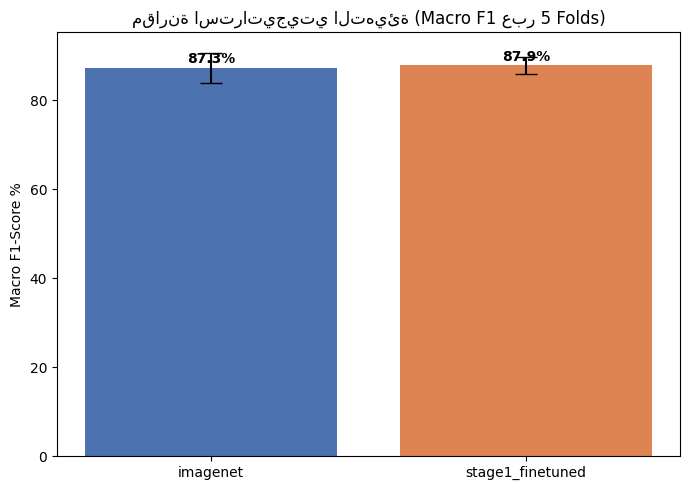


🏆 الاستراتيجية الأفضل: stage1_finetuned (Macro F1 = 87.88%)


In [ ]:
import pandas as pd

results_df = pd.DataFrame(all_fold_results)

summary = results_df.groupby("init_strategy").agg(
    Accuracy_mean=("accuracy", "mean"), Accuracy_std=("accuracy", "std"),
    MacroF1_mean=("macro_f1", "mean"), MacroF1_std=("macro_f1", "std"),
)

print("=" * 70)
print("مقارنة استراتيجيتي التهيئة (متوسط ± انحراف معياري عبر 5 Folds):")
print("=" * 70)
print(summary.round(2).to_string())

summary.to_csv(os.path.join(RESULTS_DIR, "init_strategy_comparison.csv"))

# Bar chart بالـ error bars
fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(summary))
ax.bar(x, summary["MacroF1_mean"], yerr=summary["MacroF1_std"], capsize=8, color=["#4C72B0", "#DD8452"])
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("Macro F1-Score %")
ax.set_title("مقارنة استراتيجيتي التهيئة (Macro F1 عبر 5 Folds)")
for i, v in enumerate(summary["MacroF1_mean"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "init_strategy_comparison.png"), dpi=150)
plt.show()

best_strategy = summary["MacroF1_mean"].idxmax()
print(f"\n🏆 الاستراتيجية الأفضل: {best_strategy} (Macro F1 = {summary.loc[best_strategy, 'MacroF1_mean']:.2f}%)")


## 12) إعادة تدريب نهائية بالاستراتيجية الأفضل على كل الـ Pool + تقييم على Hold-out Test
دي المرة الوحيدة اللي بنلمس فيها الـ Hold-out Test - تقييم نهائي غير متحيز.

إعادة تدريب نهائي باستخدام: stage1_finetuned
على كل الـ Pool (571 صورة) بدون تقسيم K-Fold هالمرة

stage1_finetuned_foldFINAL
   تم تحميل 572 طبقة من الـ backbone بنجاح من Stage-1.
   تم تخطي 2 طبقة (رأس التصنيف القديم - هيتعلم من جديد).
  Epoch 001 | train_acc=35.5% | val_loss=1.1115 val_acc=32.8% ✅
  Epoch 002 | train_acc=39.4% | val_loss=1.0883 val_acc=41.4% ✅
  Epoch 003 | train_acc=43.9% | val_loss=1.0712 val_acc=44.8% ✅
  Epoch 004 | train_acc=49.9% | val_loss=1.0519 val_acc=56.9% ✅
  Epoch 005 | train_acc=51.9% | val_loss=1.0435 val_acc=58.6% ✅
  Epoch 006 | train_acc=62.8% | val_loss=0.8674 val_acc=63.8% ✅
  Epoch 007 | train_acc=74.7% | val_loss=0.7132 val_acc=69.0% ✅
  Epoch 008 | train_acc=80.1% | val_loss=0.6560 val_acc=75.9% ✅
  Epoch 009 | train_acc=83.8% | val_loss=0.5835 val_acc=77.6% ✅
  Epoch 010 | train_acc=88.3% | val_loss=0.5626 val_acc=84.5% ✅
  Epoch 011 | train_acc=91.2% | val_loss=0.5363 val_acc=87.9% ✅
  Epoch 013 | train_acc=94.0% | val_loss=0.5239 val_acc=86.

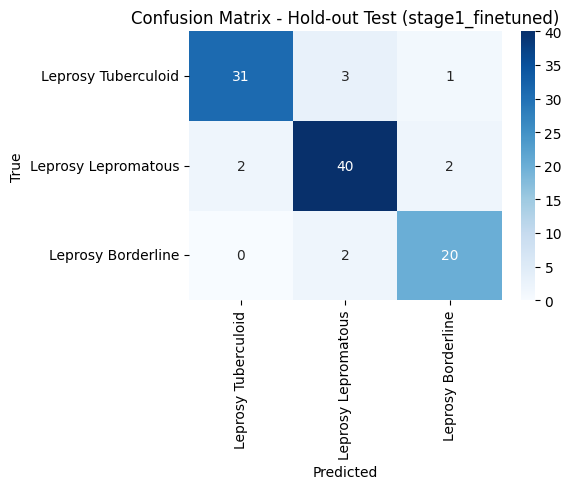

In [ ]:
print(f"إعادة تدريب نهائي باستخدام: {best_strategy}")
print(f"على كل الـ Pool ({len(pool_paths)} صورة) بدون تقسيم K-Fold هالمرة")

# تقسيم بسيط train/val داخلي بس عشان الـ Early Stopping (90/10 من الـ Pool)
from sklearn.model_selection import train_test_split as _tts
final_train_p, final_val_p, final_train_l, final_val_l = _tts(
    pool_paths, pool_labels, test_size=0.10, stratify=pool_labels, random_state=RANDOM_SEED
)

final_result = train_one_fold(best_strategy, "FINAL", final_train_p, final_train_l, final_val_p, final_val_l)

# تحميل الموديل النهائي وتقييمه على الـ Hold-out Test (منقولش منه قبل كده خالص)
final_checkpoint = os.path.join(CHECKPOINTS_DIR, f"{best_strategy}_foldFINAL_best.pt")
final_model, _ = build_model(best_strategy)
final_model.load_state_dict(torch.load(final_checkpoint, map_location=DEVICE))
final_model.to(DEVICE)

_, test_tf = get_transforms()
test_ds = LeprosySubtypeDataset(test_paths, test_labels, test_tf)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

test_preds, test_true = get_val_predictions(final_model, test_loader, DEVICE)

precision, recall, f1, support = precision_recall_fscore_support(
    test_true, test_preds, labels=list(range(NUM_CLASSES)), zero_division=0
)
test_acc = accuracy_score(test_true, test_preds) * 100

print("\n" + "=" * 70)
print("🏁 النتيجة النهائية على Hold-out Test (غير متحيزة تمامًا):")
print("=" * 70)
final_report = pd.DataFrame({
    "Subtype": [IDX_TO_SUBTYPE[i] for i in range(NUM_CLASSES)],
    "Precision": precision * 100, "Recall": recall * 100, "F1": f1 * 100, "Support": support,
})
print(final_report.round(2).to_string(index=False))
print(f"\nAccuracy الكلية: {test_acc:.2f}%")
print(f"Macro F1 الكلية: {f1.mean()*100:.2f}%")

final_report.to_csv(os.path.join(RESULTS_DIR, "final_holdout_test_report.csv"), index=False)

# Confusion Matrix 3x3
import seaborn as sns
cm = confusion_matrix(test_true, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[IDX_TO_SUBTYPE[i] for i in range(NUM_CLASSES)],
            yticklabels=[IDX_TO_SUBTYPE[i] for i in range(NUM_CLASSES)])
plt.title(f"Confusion Matrix - Hold-out Test ({best_strategy})")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "final_holdout_confusion_matrix.png"), dpi=150)
plt.show()
